In [1]:
path = '/content/dermatology_with_columns.csv'

# Basic Libraries
import numpy as np
import pandas as pd

# Data Preprocessing
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,precision_score,recall_score
)

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,

)

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping


# Warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(path)

df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

In [4]:
df.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [5]:
df.dtypes

,0
erythema,int64
scaling,int64
definite_borders,int64
itching,int64
koebner_phenomenon,int64
polygonal_papules,int64
follicular_papules,int64
oral_mucosal_involvement,int64
knee_and_elbow_involvement,int64
scalp_involvement,int64


In [6]:
df.isna().sum()

,0
erythema,0
scaling,0
definite_borders,0
itching,0
koebner_phenomenon,0
polygonal_papules,0
follicular_papules,0
oral_mucosal_involvement,0
knee_and_elbow_involvement,0
scalp_involvement,0


In [8]:
#the age is an object while it has to be an integer lets diagnose this problem

df['age'].unique()

array(['55', '8', '26', '40', '45', '41', '18', '57', '22', '30', '20',
       '21', '10', '65', '38', '23', '17', '51', '42', '44', '33', '43',
       '50', '34', '?', '15', '46', '62', '35', '48', '12', '52', '60',
       '32', '19', '29', '25', '36', '13', '27', '31', '28', '64', '39',
       '47', '16', '0', '7', '70', '37', '61', '67', '56', '53', '24',
       '58', '49', '63', '68', '9', '75'], dtype=object)

In [9]:
df[df['age']=='?']

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
33,2,2,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,?,1
34,2,1,0,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,?,4
35,2,2,1,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,?,2
36,2,1,2,3,2,3,0,2,0,0,...,0,2,0,2,0,0,0,3,?,3
262,2,1,0,2,0,0,0,0,0,0,...,0,0,2,0,0,0,3,0,?,5
263,1,1,1,3,0,0,0,0,0,0,...,0,0,3,0,0,0,2,0,?,5
264,1,1,0,2,0,0,0,0,1,0,...,0,0,2,0,0,0,3,0,?,5
265,1,1,0,3,0,0,0,0,0,0,...,0,0,2,0,0,0,3,0,?,5


#replace

In [14]:
df[df['age']!='?']['age'].astype(int).median()

35.0

In [16]:
df['age'] = df['age'].apply(lambda x:35 if x == '?' else int(x))

In [18]:
df['age'].unique()

array([55,  8, 26, 40, 45, 41, 18, 57, 22, 30, 20, 21, 10, 65, 38, 23, 17,
       51, 42, 44, 33, 43, 50, 34, 35, 15, 46, 62, 48, 12, 52, 60, 32, 19,
       29, 25, 36, 13, 27, 31, 28, 64, 39, 47, 16,  0,  7, 70, 37, 61, 67,
       56, 53, 24, 58, 49, 63, 68,  9, 75])

In [19]:
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [20]:
df.shape

(366, 35)

In [21]:
df['class'].unique()

array([2, 1, 3, 5, 4, 6])

<Axes: xlabel='class'>

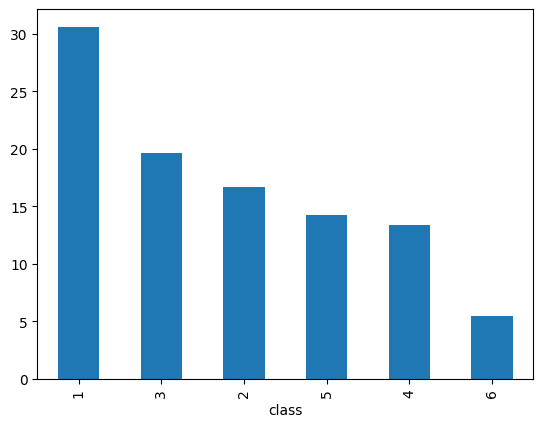

In [25]:
(df['class'].value_counts(normalize=True)*100).plot.bar()

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
# Select only numerical columns
num_cols = df.select_dtypes('number').columns

# IQR Capping
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Capping Outliers
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("Outlier treatment using IQR capping completed.")

Outlier treatment using IQR capping completed.


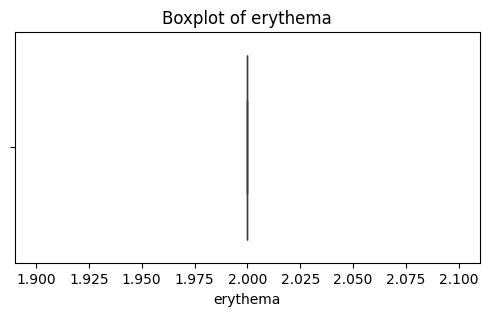

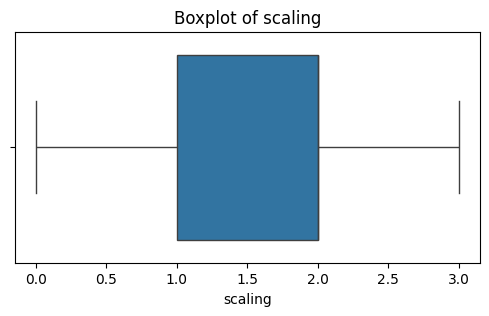

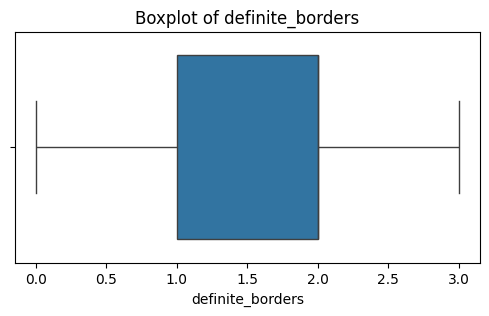

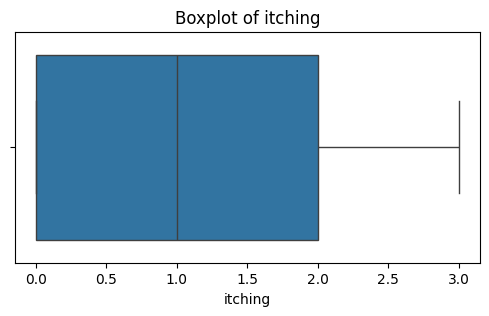

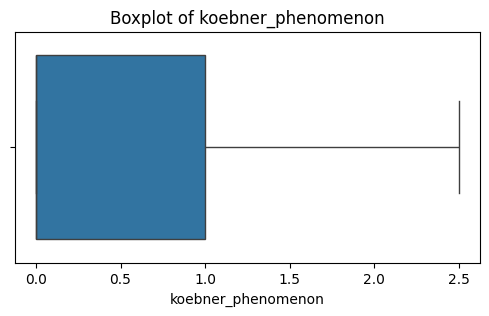

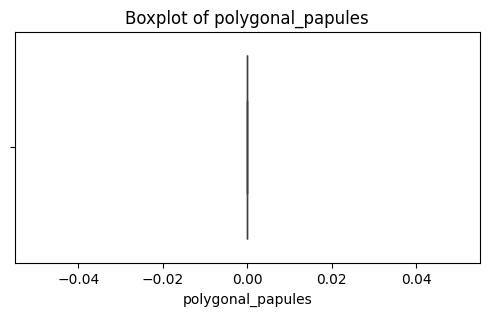

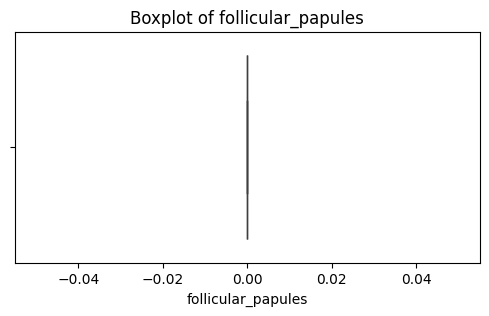

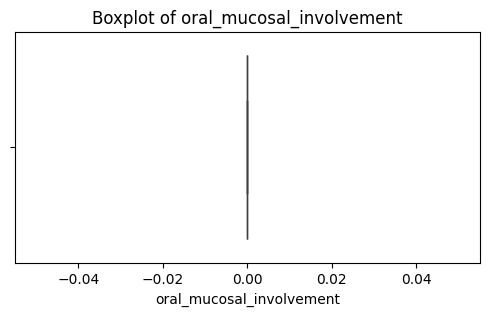

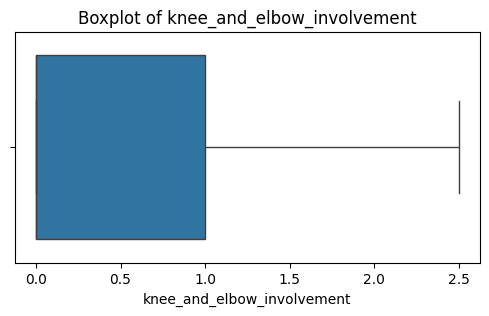

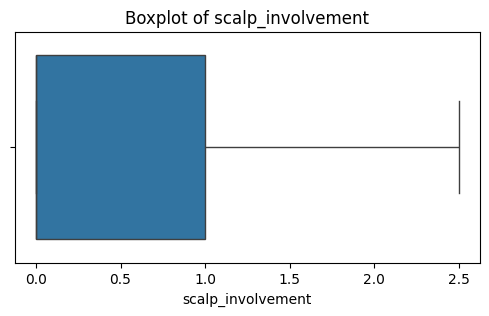

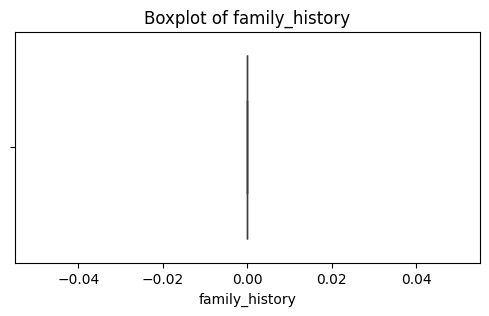

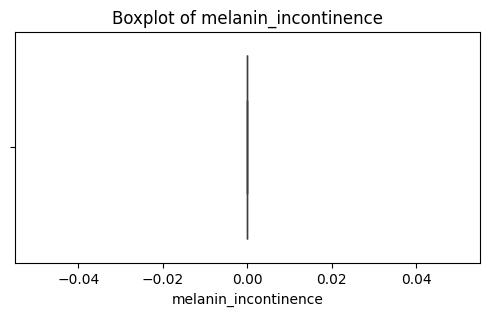

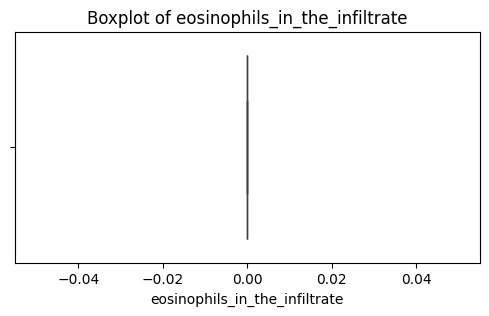

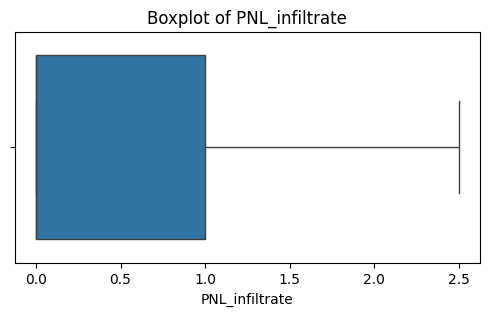

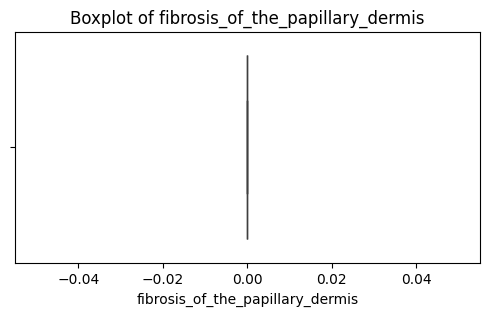

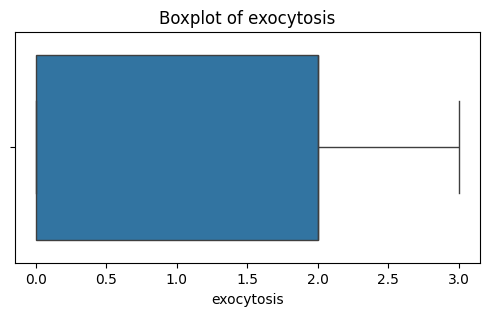

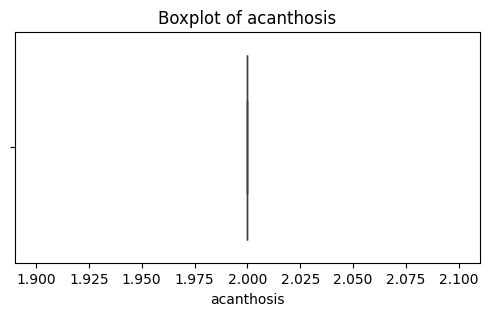

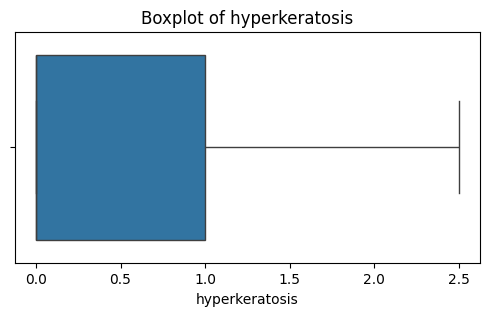

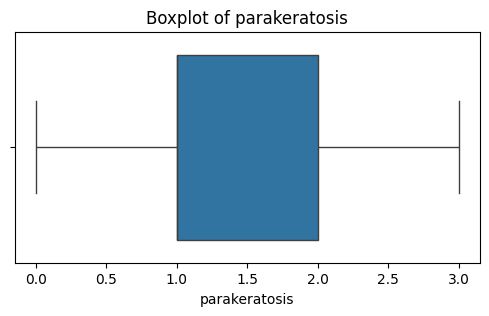

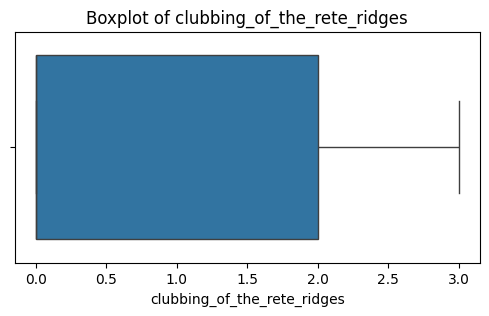

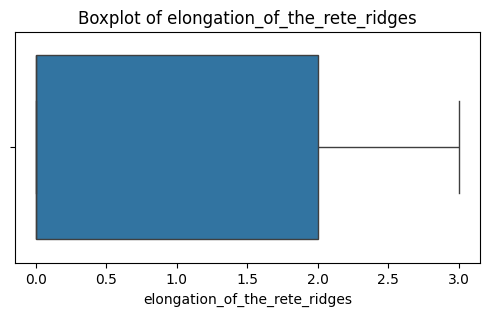

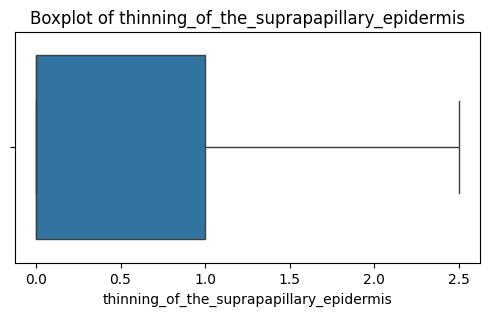

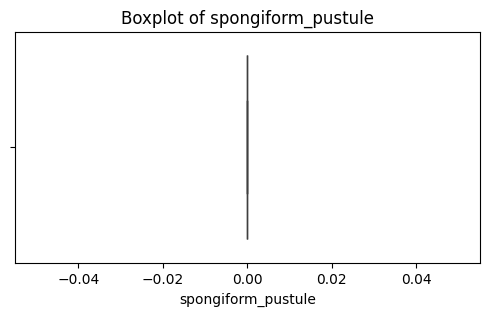

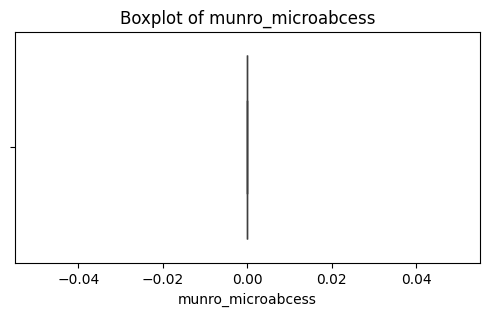

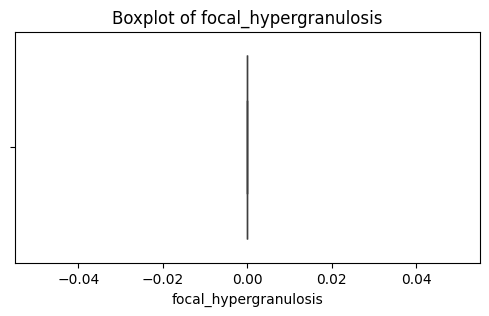

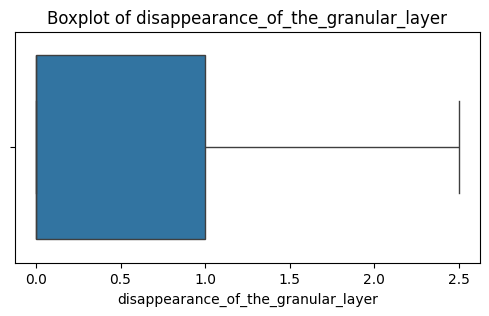

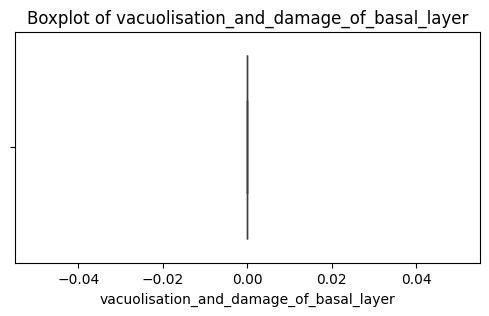

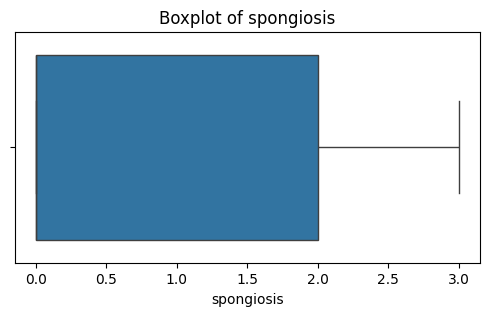

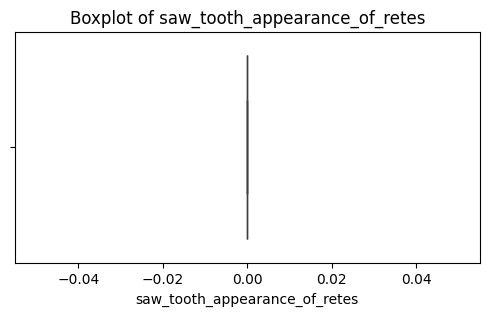

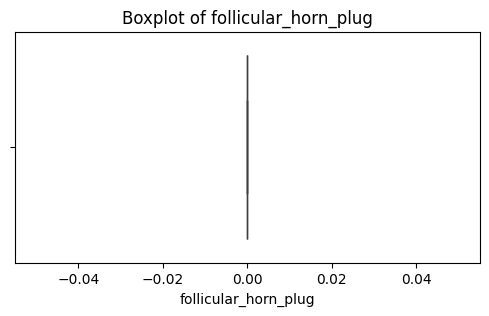

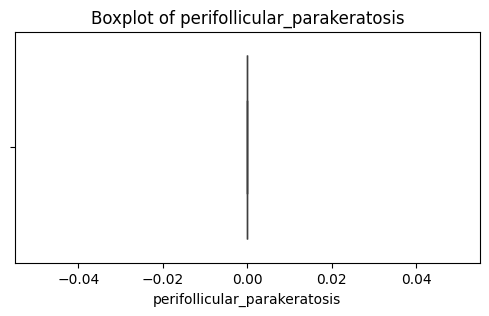

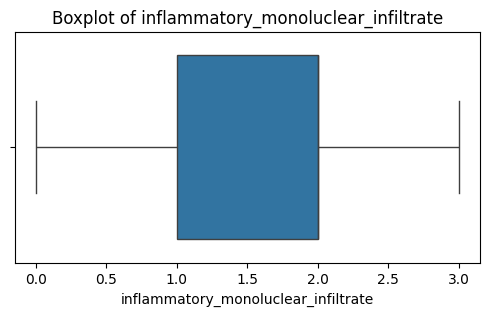

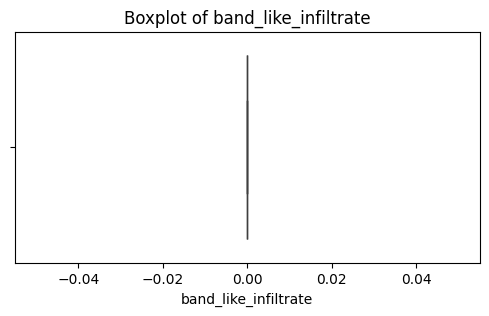

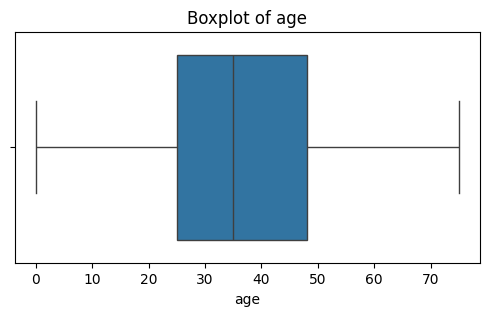

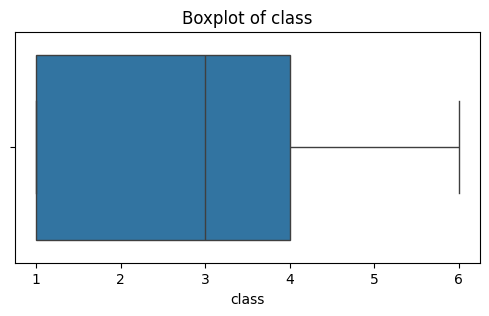

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns


# Boxplots
for col in num_cols:

    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

In [29]:
df.columns

Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
       'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis',
       'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges',
       'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_of_the_granular_layer',
       'vacuolisation_and_damage_of_basal_layer', 'spongiosis',
       'saw_tooth_appearance_of_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_monoluclear_infiltrate',
       'band_like_infiltrate', 'age', 'class'],
      dtype='object')

In [31]:
df['band_like_infiltrate'].unique()

array([0.])

In [36]:
#we can see that some features are having no deviation at all so we gotta look at it and diagnose this issue as well

cols_to_drop = []
for col in df.columns.tolist():
  if len(df[col].unique())==1:
    print(col,df[col].unique())
    cols_to_drop.append(col)


erythema [2.]
polygonal_papules [0.]
follicular_papules [0.]
oral_mucosal_involvement [0.]
family_history [0.]
melanin_incontinence [0.]
eosinophils_in_the_infiltrate [0.]
fibrosis_of_the_papillary_dermis [0.]
acanthosis [2.]
spongiform_pustule [0.]
munro_microabcess [0.]
focal_hypergranulosis [0.]
vacuolisation_and_damage_of_basal_layer [0.]
saw_tooth_appearance_of_retes [0.]
follicular_horn_plug [0.]
perifollicular_parakeratosis [0.]
band_like_infiltrate [0.]


In [37]:
cols_to_drop

['erythema',
 'polygonal_papules',
 'follicular_papules',
 'oral_mucosal_involvement',
 'family_history',
 'melanin_incontinence',
 'eosinophils_in_the_infiltrate',
 'fibrosis_of_the_papillary_dermis',
 'acanthosis',
 'spongiform_pustule',
 'munro_microabcess',
 'focal_hypergranulosis',
 'vacuolisation_and_damage_of_basal_layer',
 'saw_tooth_appearance_of_retes',
 'follicular_horn_plug',
 'perifollicular_parakeratosis',
 'band_like_infiltrate']

In [38]:
df.drop(cols_to_drop,inplace=True,axis=1)

In [39]:
df.shape

(366, 18)

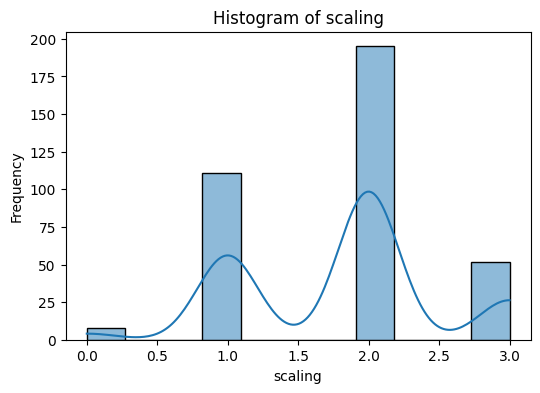

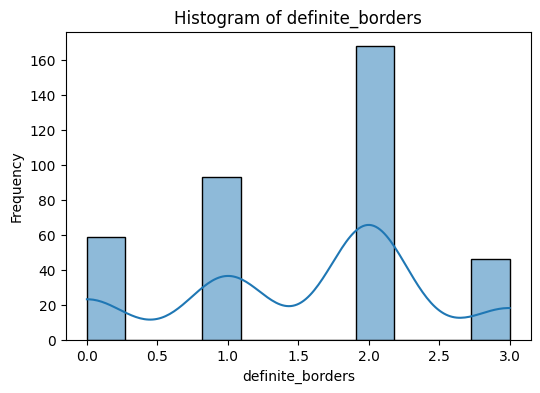

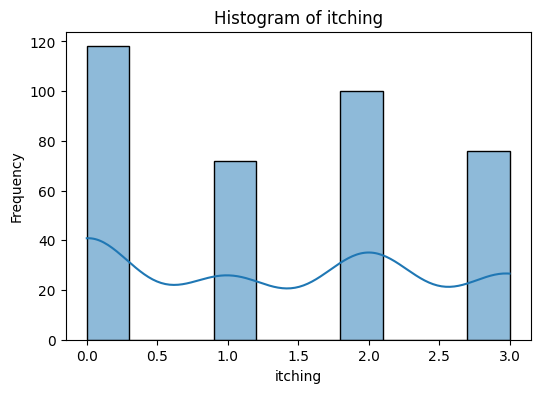

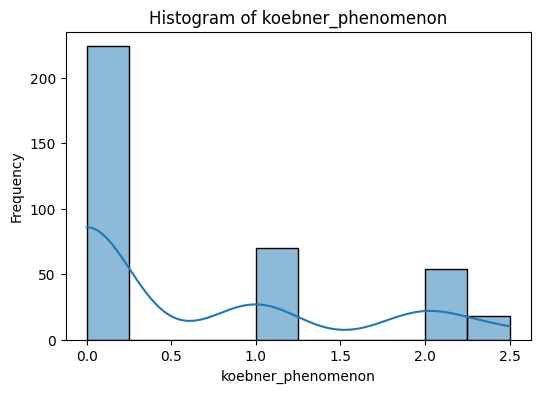

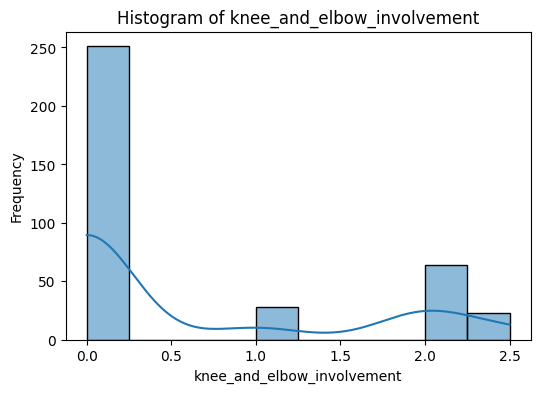

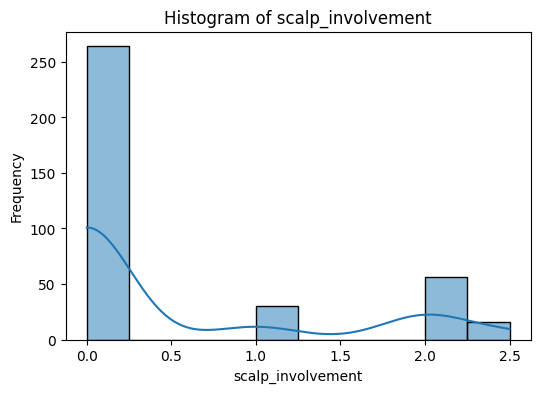

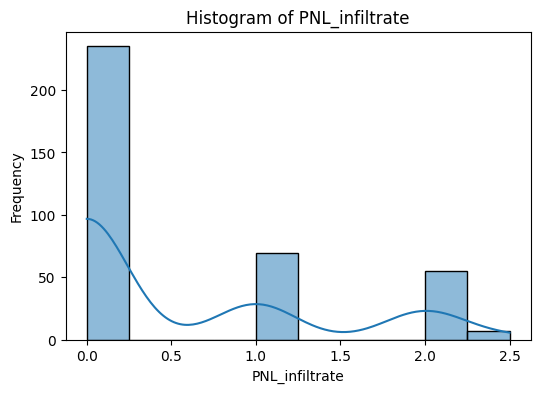

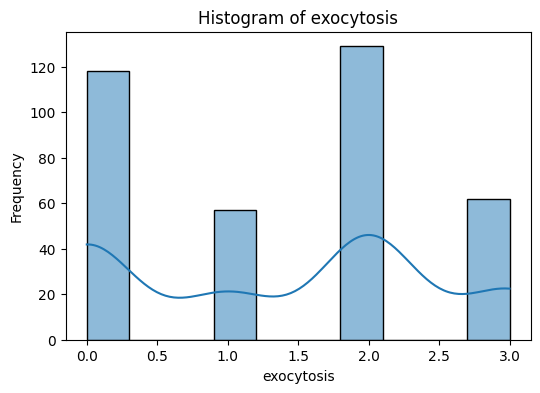

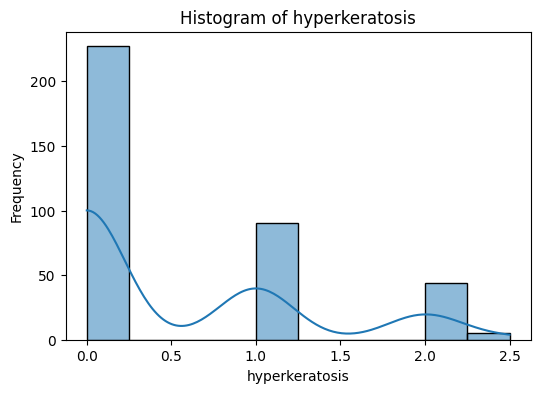

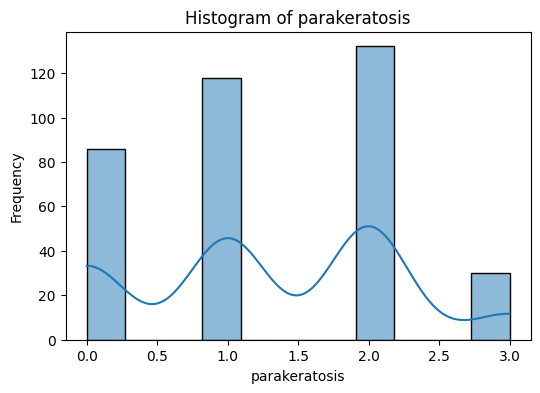

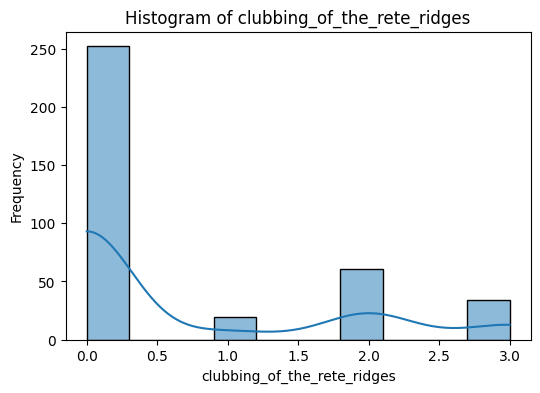

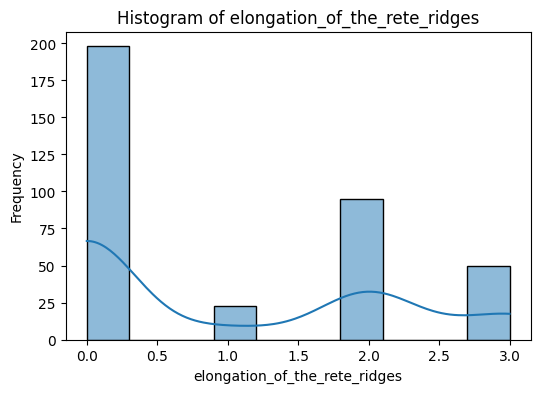

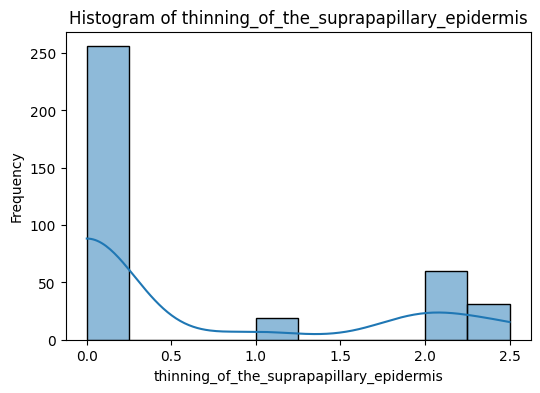

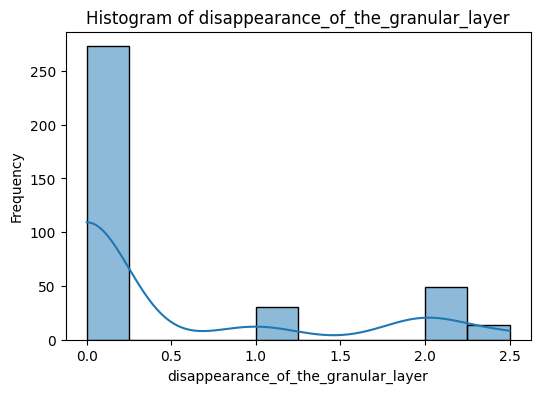

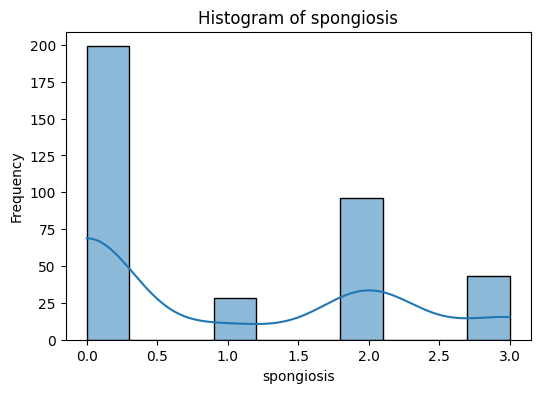

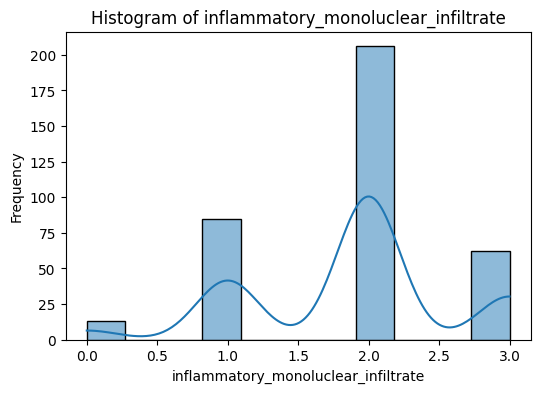

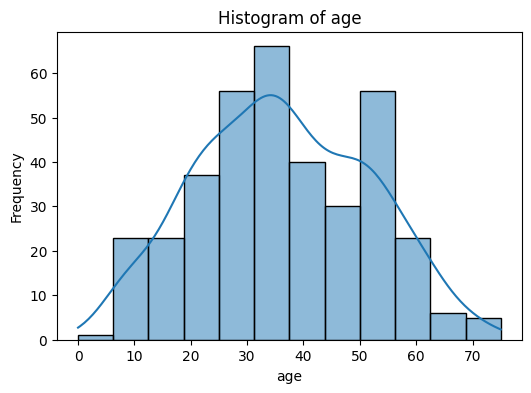

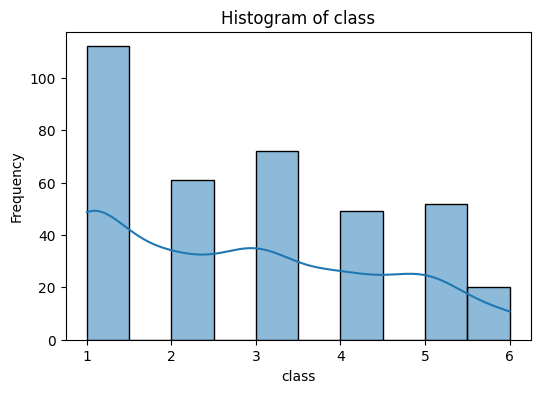

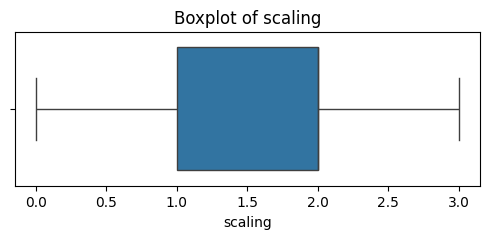

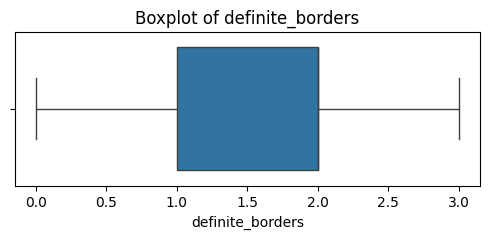

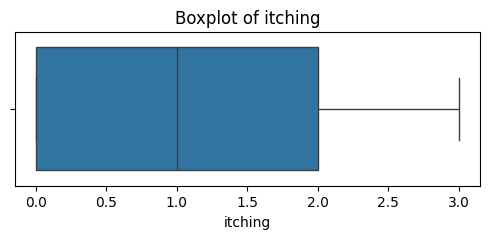

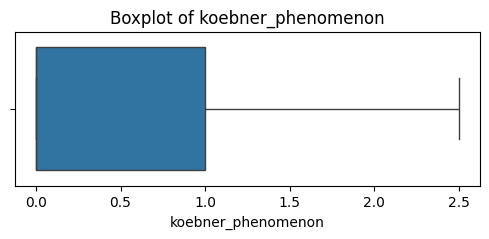

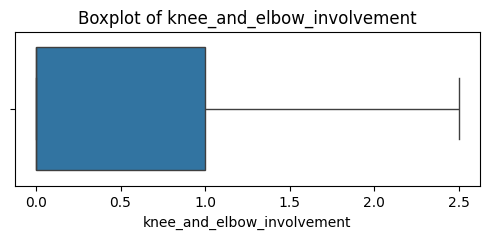

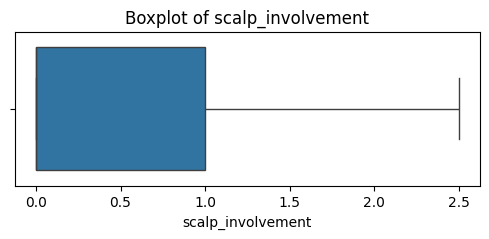

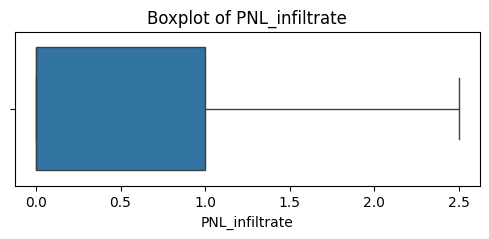

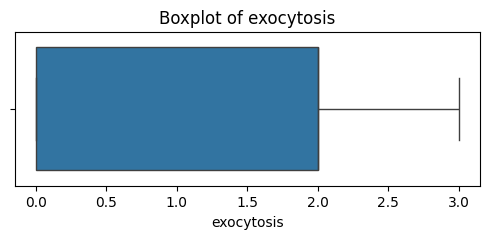

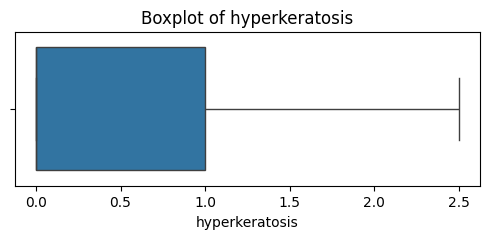

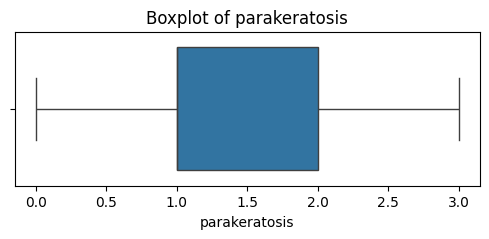

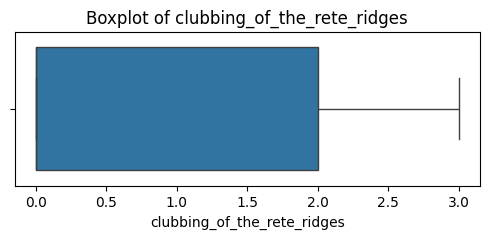

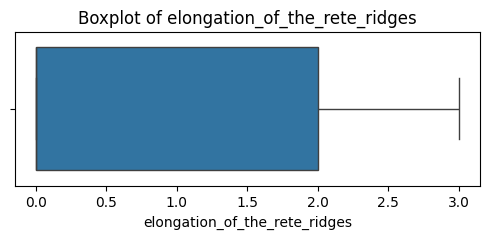

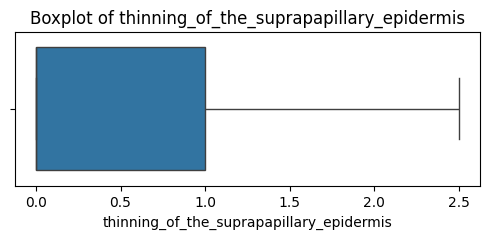

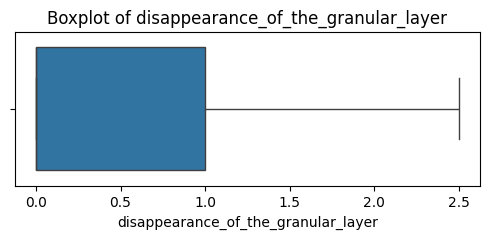

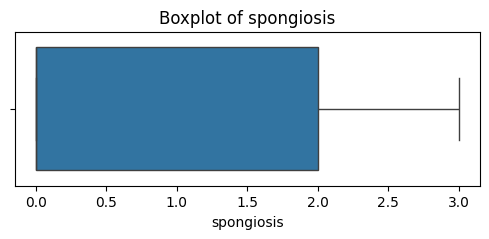

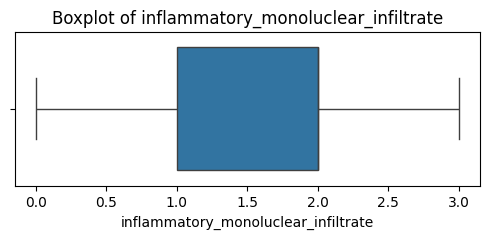

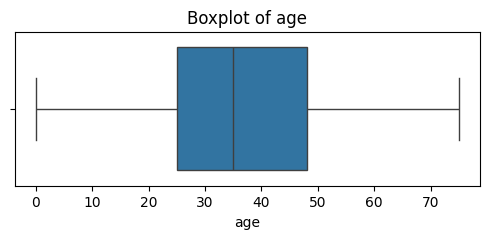

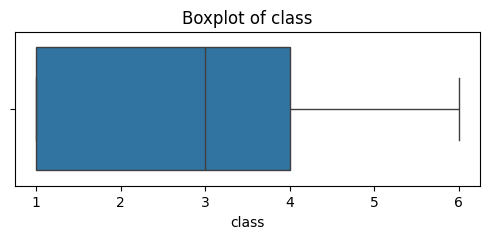


Frequency Distribution of scaling

scaling
2.0    195
1.0    111
3.0     52
0.0      8
Name: count, dtype: int64

Frequency Distribution of definite_borders

definite_borders
2.0    168
1.0     93
0.0     59
3.0     46
Name: count, dtype: int64

Frequency Distribution of itching

itching
0.0    118
2.0    100
3.0     76
1.0     72
Name: count, dtype: int64

Frequency Distribution of koebner_phenomenon

koebner_phenomenon
0.0    224
1.0     70
2.0     54
2.5     18
Name: count, dtype: int64

Frequency Distribution of knee_and_elbow_involvement

knee_and_elbow_involvement
0.0    251
2.0     64
1.0     28
2.5     23
Name: count, dtype: int64

Frequency Distribution of scalp_involvement

scalp_involvement
0.0    264
2.0     56
1.0     30
2.5     16
Name: count, dtype: int64

Frequency Distribution of PNL_infiltrate

PNL_infiltrate
0.0    235
1.0     69
2.0     55
2.5      7
Name: count, dtype: int64

Frequency Distribution of exocytosis

exocytosis
2.0    129
0.0    118
3.0     62
1.0    

In [42]:
# ================================
# UNIVARIATE ANALYSIS
# ================================

num_cols = df.select_dtypes('number').columns

# Histograms + Density Plots
for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(df[col], kde=True)

    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()


# Boxplots
for col in num_cols:

    plt.figure(figsize=(6,2))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()


# Frequency Distribution
for col in num_cols:

    print(f"\nFrequency Distribution of {col}\n")
    print(df[col].value_counts())

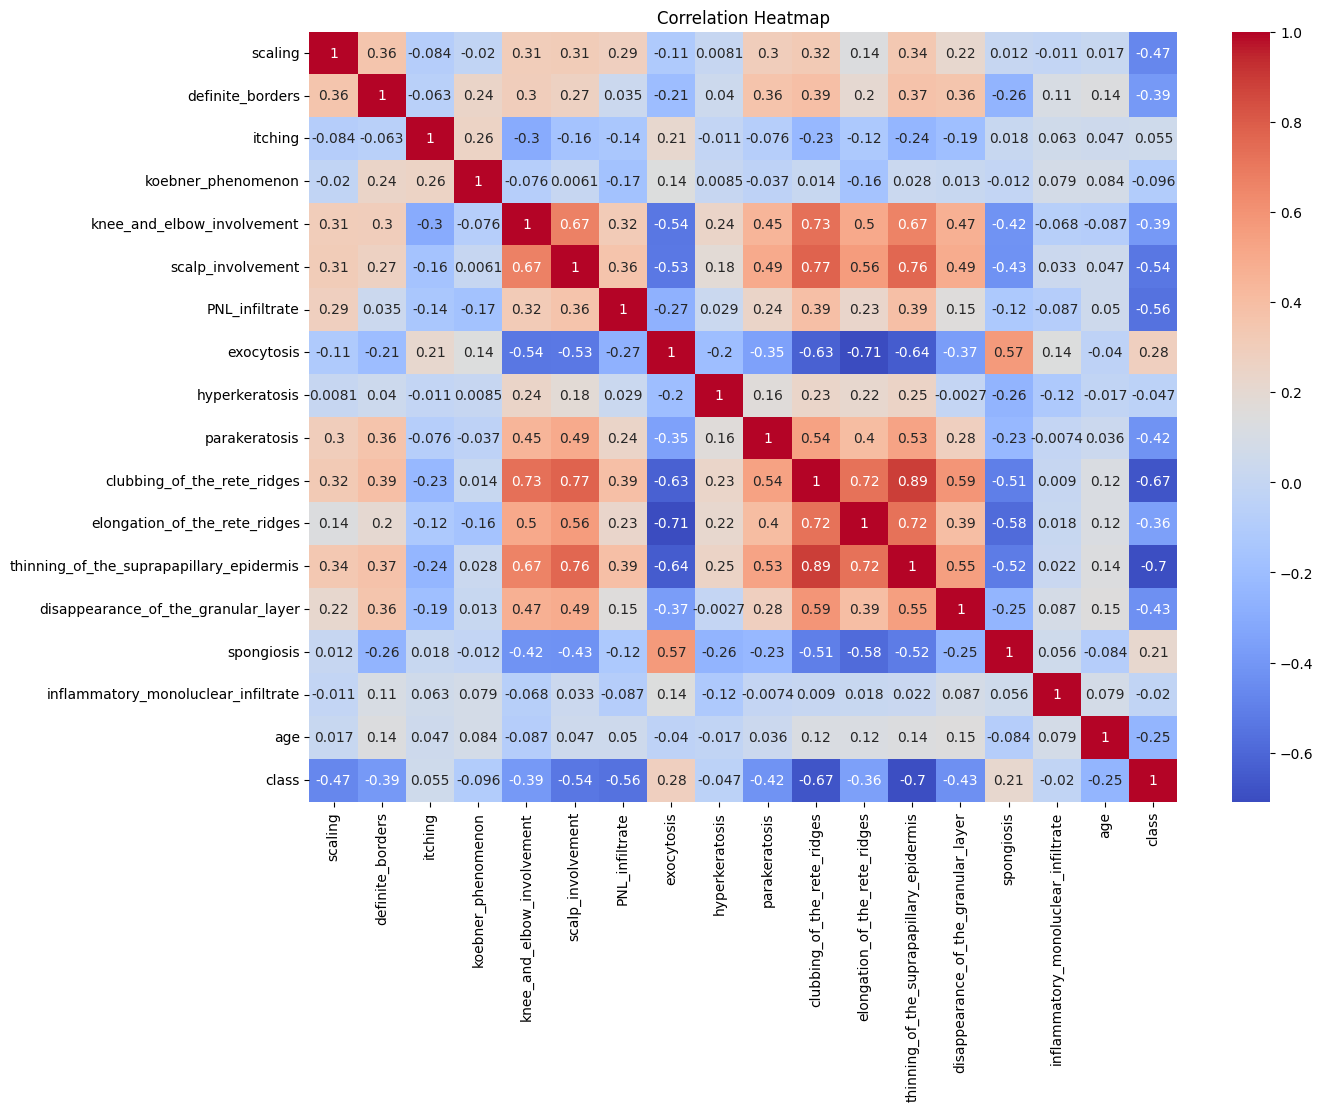

In [44]:
# ================================
# BIVARIATE ANALYSIS
# ================================

# Correlation Heatmap
plt.figure(figsize=(14,10))

sns.heatmap(df.corr(), cmap="coolwarm",annot=True)

plt.title("Correlation Heatmap")

plt.show()

<Axes: >

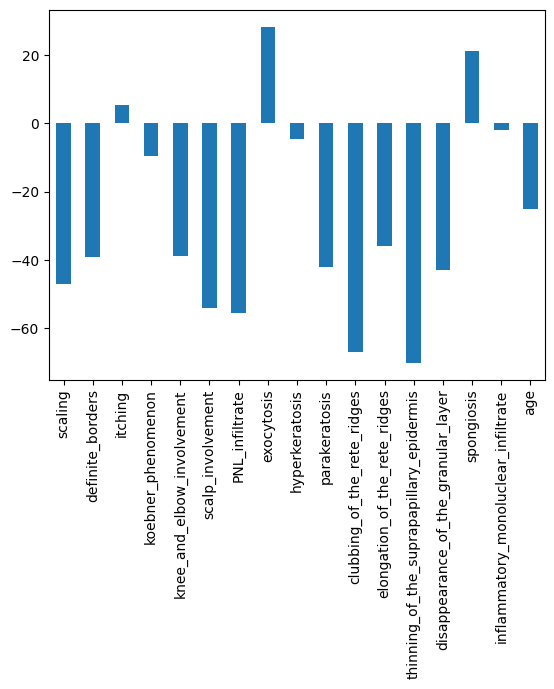

In [47]:
(df.corr()['class'].drop(['class'])*100).plot.bar()

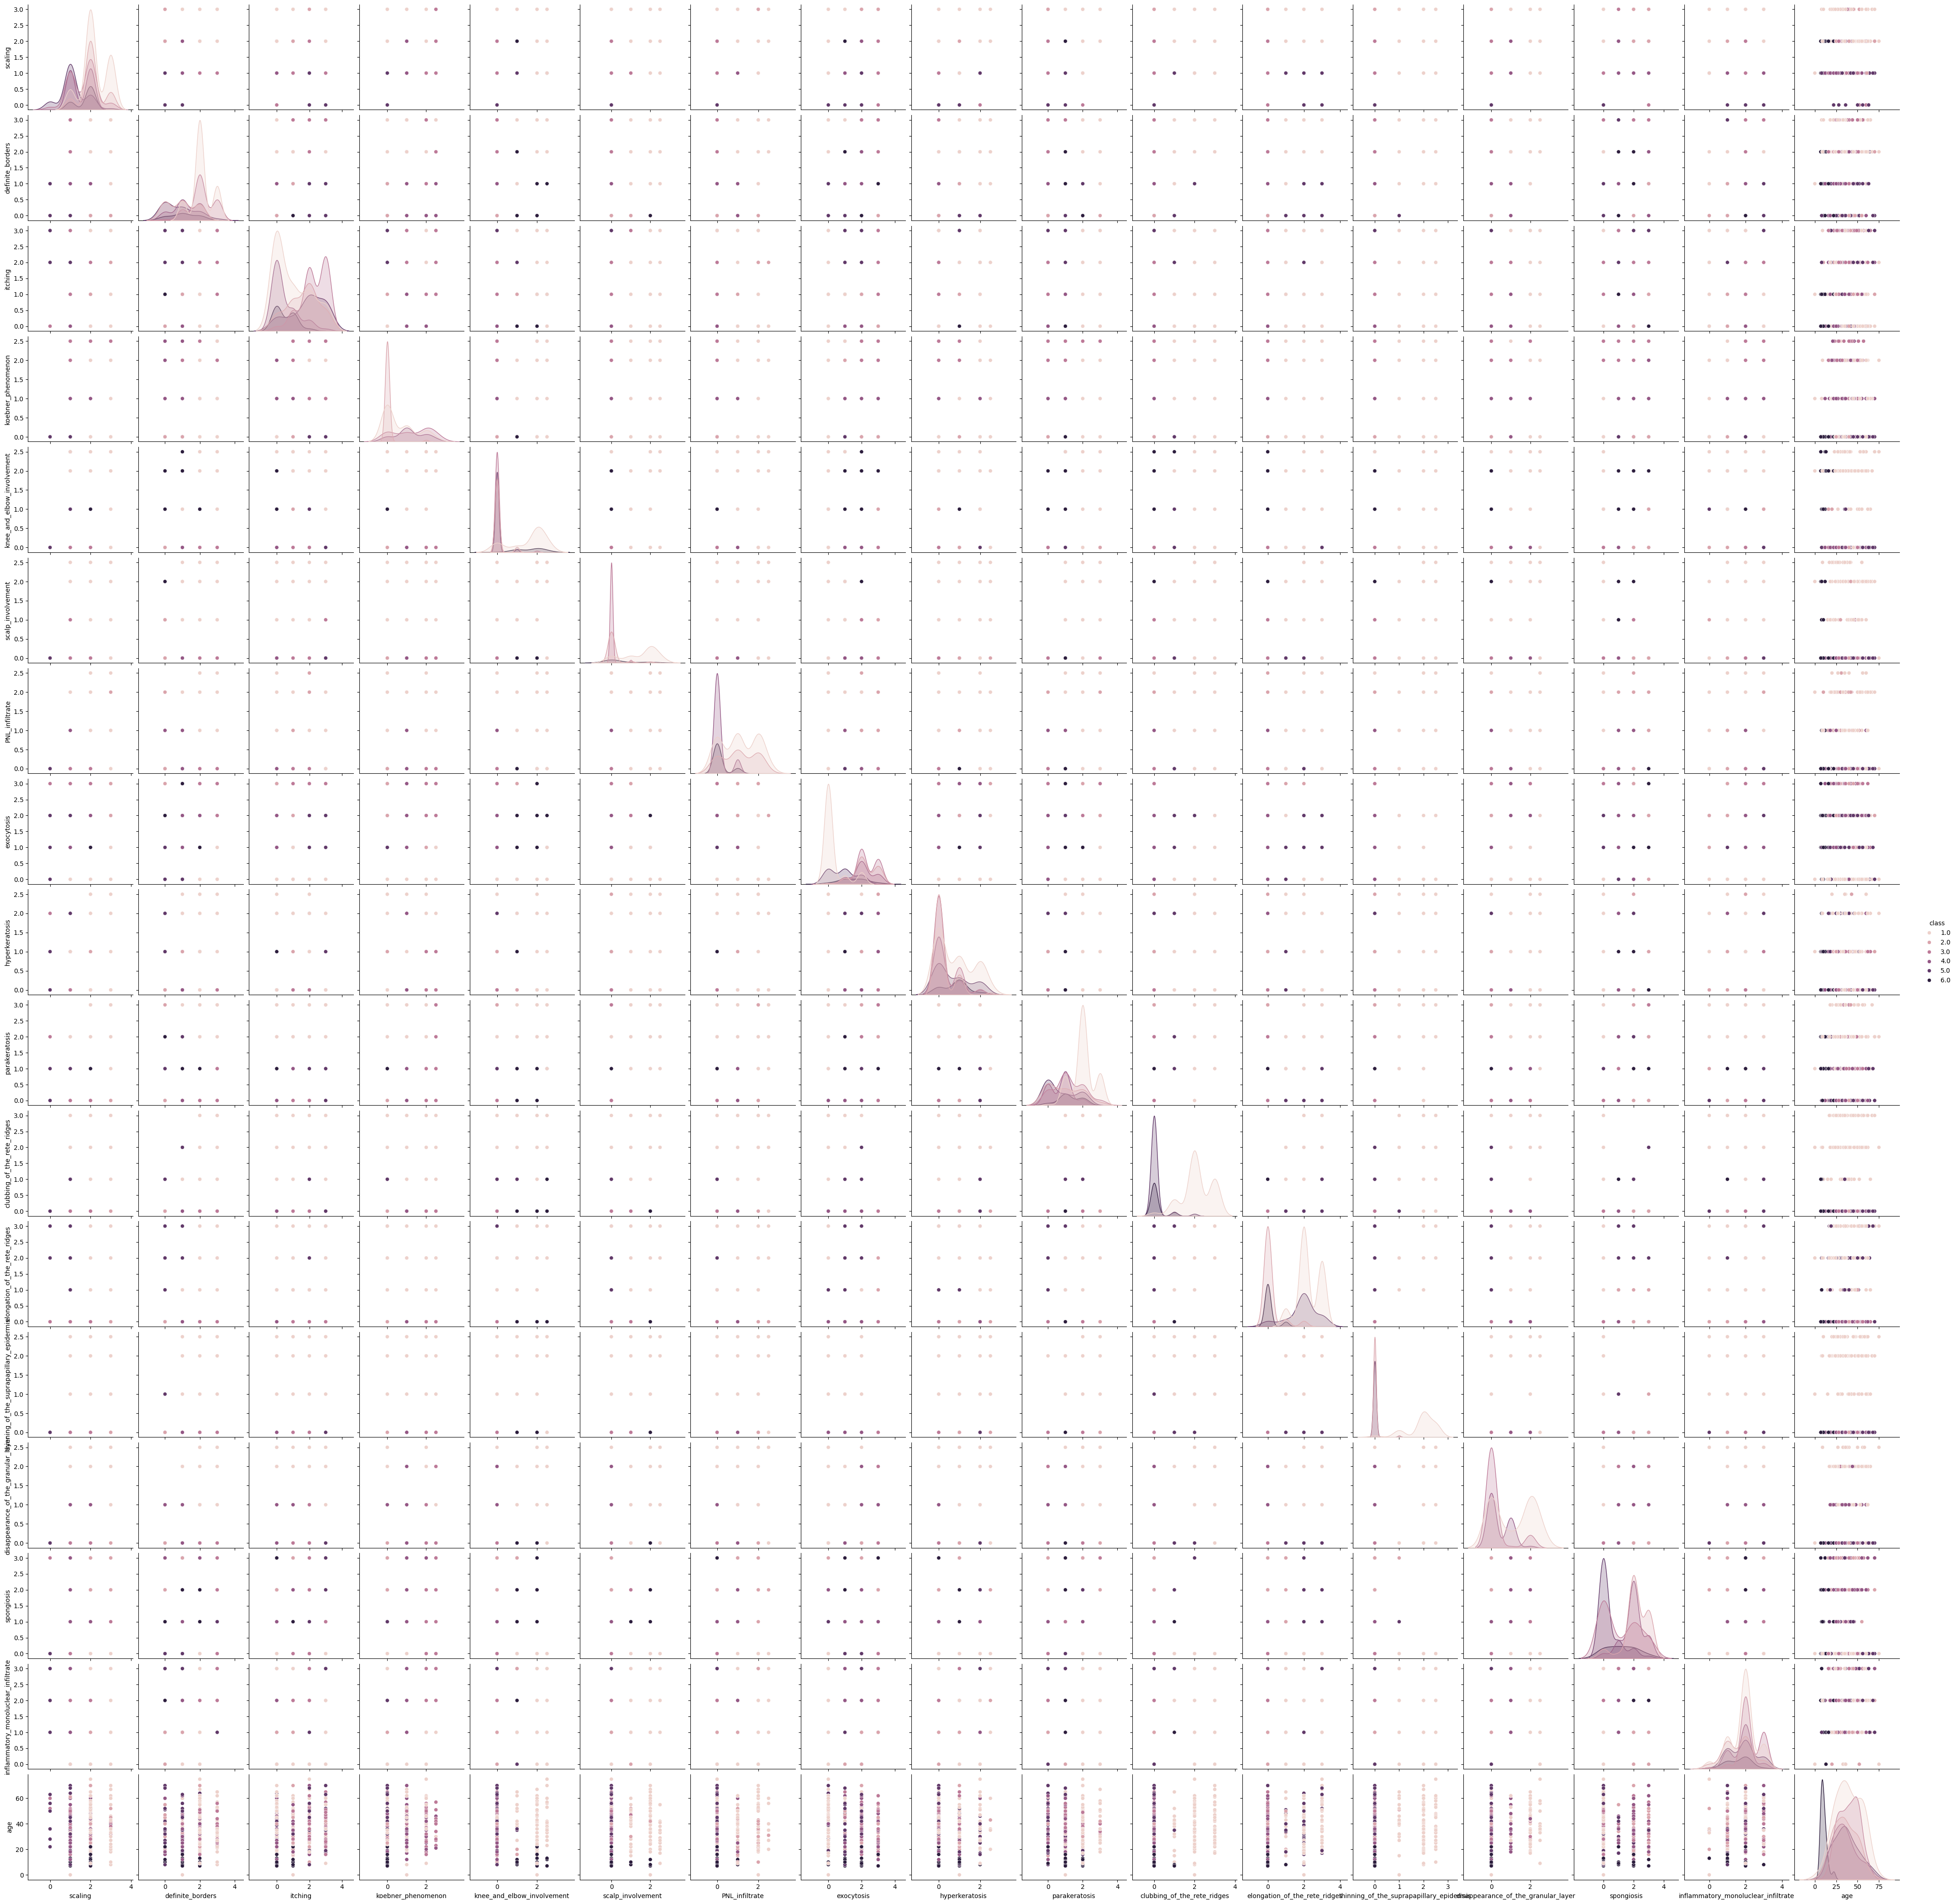

In [48]:
sns.pairplot(
    df,
    hue="class"
)

plt.show()

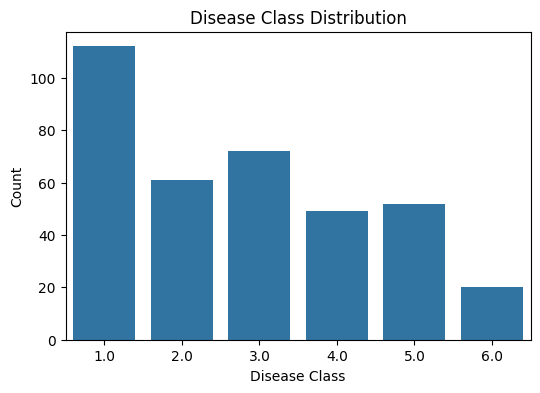

In [49]:
# ================================
# TARGET VARIABLE ANALYSIS
# ================================

# Disease Class Distribution
plt.figure(figsize=(6,4))

sns.countplot(x=df["class"])

plt.title("Disease Class Distribution")

plt.xlabel("Disease Class")
plt.ylabel("Count")

plt.show()

In [50]:
# ================================
# STATISTICAL ANALYSIS
# ================================

from scipy.stats import (
    pearsonr,
    spearmanr,
    chi2_contingency,
    f_oneway,
    shapiro
)

# Numerical columns
num_cols = df.select_dtypes('number').columns.tolist()

# Remove target column
num_cols.remove("class")

In [53]:
from scipy.stats import f_oneway

# Numerical columns

num_cols = df.select_dtypes('number').columns.tolist()

# Remove target column
num_cols.remove("class")

print("ANOVA TEST\n")

for col in num_cols:

    groups = [
        df[df["class"] == c][col]
        for c in df["class"].unique()
    ]

    stat, p_value = f_oneway(*groups)

    print(f"{col}")
    print(f"P-value: {p_value:.4f}")

    if p_value < 0.05:
        print(f"col {col} has a significant impact on the target")
    else:
        print(f"col {col} has no impact on the target")

    print("-" * 40)

ANOVA TEST

scaling
P-value: 0.0000
col scaling has a significant impact on the target
----------------------------------------
definite_borders
P-value: 0.0000
col definite_borders has a significant impact on the target
----------------------------------------
itching
P-value: 0.0000
col itching has a significant impact on the target
----------------------------------------
koebner_phenomenon
P-value: 0.0000
col koebner_phenomenon has a significant impact on the target
----------------------------------------
knee_and_elbow_involvement
P-value: 0.0000
col knee_and_elbow_involvement has a significant impact on the target
----------------------------------------
scalp_involvement
P-value: 0.0000
col scalp_involvement has a significant impact on the target
----------------------------------------
PNL_infiltrate
P-value: 0.0000
col PNL_infiltrate has a significant impact on the target
----------------------------------------
exocytosis
P-value: 0.0000
col exocytosis has a significant impa

In [52]:
from scipy.stats import chi2_contingency

# Treat low unique-value columns as categorical
cat_cols = [
    col for col in df.columns
    if df[col].nunique() <= 10 and col != "class"
]

print("CHI-SQUARE TEST\n")

for col in cat_cols:

    table = pd.crosstab(df[col], df["class"])

    stat, p_value, dof, expected = chi2_contingency(table)

    print(f"{col}")
    print(f"P-value: {p_value:.4f}")

    if p_value < 0.05:
        print("Significant Association")
    else:
        print("Not Significant")

    print("-" * 40)

CHI-SQUARE TEST

scaling
P-value: 0.0000
Significant Association
----------------------------------------
definite_borders
P-value: 0.0000
Significant Association
----------------------------------------
itching
P-value: 0.0000
Significant Association
----------------------------------------
koebner_phenomenon
P-value: 0.0000
Significant Association
----------------------------------------
knee_and_elbow_involvement
P-value: 0.0000
Significant Association
----------------------------------------
scalp_involvement
P-value: 0.0000
Significant Association
----------------------------------------
PNL_infiltrate
P-value: 0.0000
Significant Association
----------------------------------------
exocytosis
P-value: 0.0000
Significant Association
----------------------------------------
hyperkeratosis
P-value: 0.0000
Significant Association
----------------------------------------
parakeratosis
P-value: 0.0000
Significant Association
----------------------------------------
clubbing_of_the_rete_

| Feature                                | P-value | Significance |
| -------------------------------------- | ------- | ------------ |
| scaling                                | 0.0000  | Significant  |
| definite_borders                       | 0.0000  | Significant  |
| itching                                | 0.0000  | Significant  |
| koebner_phenomenon                     | 0.0000  | Significant  |
| knee_and_elbow_involvement             | 0.0000  | Significant  |
| scalp_involvement                      | 0.0000  | Significant  |
| PNL_infiltrate                         | 0.0000  | Significant  |
| exocytosis                             | 0.0000  | Significant  |
| hyperkeratosis                         | 0.0000  | Significant  |
| parakeratosis                          | 0.0000  | Significant  |
| clubbing_of_the_rete_ridges            | 0.0000  | Significant  |
| elongation_of_the_rete_ridges          | 0.0000  | Significant  |
| thinning_of_the_suprapillary_epidermis | 0.0000  | Significant  |
| disappearance_of_the_granular_layer    | 0.0000  | Significant  |
| spongiosis                             | 0.0000  | Significant  |
| inflammatory_monoluclear_infiltrate    | 0.0000  | Significant  |
| age                                    | 0.0000  | Significant  |


| Feature                                | P-value | Significance |
| -------------------------------------- | ------- | ------------ |
| scaling                                | 0.0000  | Significant  |
| definite_borders                       | 0.0000  | Significant  |
| itching                                | 0.0000  | Significant  |
| koebner_phenomenon                     | 0.0000  | Significant  |
| knee_and_elbow_involvement             | 0.0000  | Significant  |
| scalp_involvement                      | 0.0000  | Significant  |
| PNL_infiltrate                         | 0.0000  | Significant  |
| exocytosis                             | 0.0000  | Significant  |
| hyperkeratosis                         | 0.0000  | Significant  |
| parakeratosis                          | 0.0000  | Significant  |
| clubbing_of_the_rete_ridges            | 0.0000  | Significant  |
| elongation_of_the_rete_ridges          | 0.0000  | Significant  |
| thinning_of_the_suprapillary_epidermis | 0.0000  | Significant  |
| disappearance_of_the_granular_layer    | 0.0000  | Significant  |
| spongiosis                             | 0.0000  | Significant  |
| inflammatory_monoluclear_infiltrate    | 0.0000  | Significant  |
| age                                    | 0.0000  | Significant  |


In [54]:
from scipy.stats import shapiro

print("SHAPIRO-WILK TEST\n")

for col in num_cols:

    stat, p_value = shapiro(df[col])

    print(f"{col}")
    print(f"P-value: {p_value:.4f}")

    if p_value < 0.05:
        print(f"{col} is Not Normally Distributed")
    else:
        print(f"{col} is Normally Distributed")

    print("-" * 40)

SHAPIRO-WILK TEST

scaling
P-value: 0.0000
scaling is Not Normally Distributed
----------------------------------------
definite_borders
P-value: 0.0000
definite_borders is Not Normally Distributed
----------------------------------------
itching
P-value: 0.0000
itching is Not Normally Distributed
----------------------------------------
koebner_phenomenon
P-value: 0.0000
koebner_phenomenon is Not Normally Distributed
----------------------------------------
knee_and_elbow_involvement
P-value: 0.0000
knee_and_elbow_involvement is Not Normally Distributed
----------------------------------------
scalp_involvement
P-value: 0.0000
scalp_involvement is Not Normally Distributed
----------------------------------------
PNL_infiltrate
P-value: 0.0000
PNL_infiltrate is Not Normally Distributed
----------------------------------------
exocytosis
P-value: 0.0000
exocytosis is Not Normally Distributed
----------------------------------------
hyperkeratosis
P-value: 0.0000
hyperkeratosis is Not No

| Feature                                  | P-value | Distribution Status      |
| ---------------------------------------- | ------- | ------------------------ |
| scaling                                  | 0.0000  | Not Normally Distributed |
| definite_borders                         | 0.0000  | Not Normally Distributed |
| itching                                  | 0.0000  | Not Normally Distributed |
| koebner_phenomenon                       | 0.0000  | Not Normally Distributed |
| knee_and_elbow_involvement               | 0.0000  | Not Normally Distributed |
| scalp_involvement                        | 0.0000  | Not Normally Distributed |
| PNL_infiltrate                           | 0.0000  | Not Normally Distributed |
| exocytosis                               | 0.0000  | Not Normally Distributed |
| hyperkeratosis                           | 0.0000  | Not Normally Distributed |
| parakeratosis                            | 0.0000  | Not Normally Distributed |
| clubbing_of_the_rete_ridges              | 0.0000  | Not Normally Distributed |
| elongation_of_the_rete_ridges            | 0.0000  | Not Normally Distributed |
| thinning_of_the_suprapapillary_epidermis | 0.0000  | Not Normally Distributed |
| disappearance_of_the_granular_layer      | 0.0000  | Not Normally Distributed |
| spongiosis                               | 0.0000  | Not Normally Distributed |
| inflammatory_monoluclear_infiltrate      | 0.0000  | Not Normally Distributed |
| age                                      | 0.0032  | Not Normally Distributed |


In [55]:
df[num_cols].skew()

,0
scaling,-0.075176
definite_borders,-0.290783
itching,0.098205
koebner_phenomenon,0.994841
knee_and_elbow_involvement,1.077381
scalp_involvement,1.302042
PNL_infiltrate,1.097431
exocytosis,-0.008204
hyperkeratosis,1.096826
parakeratosis,0.036052


In [56]:
df[num_cols].kurtosis()

,0
scaling,-0.295196
definite_borders,-0.729475
itching,-1.415595
koebner_phenomenon,-0.525891
knee_and_elbow_involvement,-0.610963
scalp_involvement,-0.026571
PNL_infiltrate,-0.303875
exocytosis,-1.387321
hyperkeratosis,-0.102963
parakeratosis,-0.946037


In [57]:
#as we can see that shapiro returns that all the features are not normal hence wewill apply power transformer to make our features approximately normal
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

df[num_cols] = pt.fit_transform(df[num_cols])



In [58]:
df[num_cols].skew()

,0
scaling,-0.032284
definite_borders,-0.169861
itching,-0.127337
koebner_phenomenon,0.517861
knee_and_elbow_involvement,0.820088
scalp_involvement,1.000303
PNL_infiltrate,0.628739
exocytosis,-0.170171
hyperkeratosis,0.538488
parakeratosis,-0.128966


In [59]:
df.head()

,scaling,definite_borders,itching,koebner_phenomenon,knee_and_elbow_involvement,scalp_involvement,PNL_infiltrate,exocytosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,disappearance_of_the_granular_layer,spongiosis,inflammatory_monoluclear_infiltrate,age,class
0,0.285765,-1.657323,1.314850,-0.788866,1.247980,-0.620723,-0.742630,1.372323,-0.777483,-1.463920,-0.670744,-0.90591,-0.654311,-0.583201,1.391028,-1.198702,1.212397,2.0
1,1.736450,1.664958,0.636041,1.025993,1.247980,1.453442,1.169181,-0.234062,-0.777483,0.788787,1.504014,1.05125,1.555312,-0.583201,-0.900270,-1.198702,-1.994960,1.0
2,-1.134619,0.479261,1.314850,1.025993,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,0.788787,-0.670744,-0.90591,-0.654311,-0.583201,1.391028,0.138402,-0.647848,3.0
3,0.285765,0.479261,-1.274818,-0.788866,1.585555,1.663101,1.575398,-1.288990,-0.777483,1.747462,1.504014,1.05125,1.555312,1.782995,-0.900270,1.663971,0.279973,1.0
4,1.736450,0.479261,0.636041,1.432970,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,-1.463920,-0.670744,-0.90591,-0.654311,1.761182,1.087536,0.138402,0.596643,3.0


In [60]:
df.shape

(366, 18)

now give me top 4 feature's that can be engineered from the existing features such that it gives us a very amazing model and is able to uncover hidden patterns in the data

note:beware of the data leakage

In [61]:
# =========================================
# FEATURE ENGINEERING
# =========================================

# 1. Psoriasis Severity Index
df["psoriasis_severity_index"] = (
    df["scaling"] +
    df["parakeratosis"] +
    df["hyperkeratosis"] +
    df["elongation_of_the_rete_ridges"]
)

# 2. Inflammatory Activity Score
df["inflammatory_activity_score"] = (
    df["PNL_infiltrate"] +
    df["exocytosis"] +
    df["spongiosis"] +
    df["inflammatory_monoluclear_infiltrate"]
)

# 3. Epidermal Damage Ratio
df["epidermal_damage_ratio"] = (
    df["thinning_of_the_suprapapillary_epidermis"] /
    (df["hyperkeratosis"] + 1)
)

# 4. Clinical-Histopathological Interaction
df["clinical_histopathological_interaction"] = (
    df["itching"] *
    df["spongiosis"]
)



In [62]:
df.head()

,scaling,definite_borders,itching,koebner_phenomenon,knee_and_elbow_involvement,scalp_involvement,PNL_infiltrate,exocytosis,hyperkeratosis,parakeratosis,...,thinning_of_the_suprapapillary_epidermis,disappearance_of_the_granular_layer,spongiosis,inflammatory_monoluclear_infiltrate,age,class,psoriasis_severity_index,inflammatory_activity_score,epidermal_damage_ratio,clinical_histopathological_interaction
0,0.285765,-1.657323,1.314850,-0.788866,1.247980,-0.620723,-0.742630,1.372323,-0.777483,-1.463920,...,-0.654311,-0.583201,1.391028,-1.198702,1.212397,2.0,-2.861547,0.822018,-2.940498,1.828993
1,1.736450,1.664958,0.636041,1.025993,1.247980,1.453442,1.169181,-0.234062,-0.777483,0.788787,...,1.555312,-0.583201,-0.900270,-1.198702,-1.994960,1.0,2.799005,-1.163854,6.989624,-0.572609
2,-1.134619,0.479261,1.314850,1.025993,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,0.788787,...,-0.654311,-0.583201,1.391028,0.138402,-0.647848,3.0,-2.029224,0.552738,-2.940498,1.828993
3,0.285765,0.479261,-1.274818,-0.788866,1.585555,1.663101,1.575398,-1.288990,-0.777483,1.747462,...,1.555312,1.782995,-0.900270,1.663971,0.279973,1.0,2.306995,1.050108,6.989624,1.147681
4,1.736450,0.479261,0.636041,1.432970,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,-1.463920,...,-0.654311,1.761182,1.087536,0.138402,0.596643,3.0,-1.410863,0.249245,-2.940498,0.691717


In [63]:
df.columns

Index(['scaling', 'definite_borders', 'itching', 'koebner_phenomenon',
       'knee_and_elbow_involvement', 'scalp_involvement', 'PNL_infiltrate',
       'exocytosis', 'hyperkeratosis', 'parakeratosis',
       'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis',
       'disappearance_of_the_granular_layer', 'spongiosis',
       'inflammatory_monoluclear_infiltrate', 'age', 'class',
       'psoriasis_severity_index', 'inflammatory_activity_score',
       'epidermal_damage_ratio', 'clinical_histopathological_interaction'],
      dtype='object')

In [65]:
df= df[['scaling', 'definite_borders', 'itching', 'koebner_phenomenon',
       'knee_and_elbow_involvement', 'scalp_involvement', 'PNL_infiltrate',
       'exocytosis', 'hyperkeratosis', 'parakeratosis',
       'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis',
       'disappearance_of_the_granular_layer', 'spongiosis',
       'inflammatory_monoluclear_infiltrate', 'age',
       'psoriasis_severity_index', 'inflammatory_activity_score',
       'epidermal_damage_ratio', 'clinical_histopathological_interaction', 'class']]

df.head()

,scaling,definite_borders,itching,koebner_phenomenon,knee_and_elbow_involvement,scalp_involvement,PNL_infiltrate,exocytosis,hyperkeratosis,parakeratosis,...,thinning_of_the_suprapapillary_epidermis,disappearance_of_the_granular_layer,spongiosis,inflammatory_monoluclear_infiltrate,age,psoriasis_severity_index,inflammatory_activity_score,epidermal_damage_ratio,clinical_histopathological_interaction,class
0,0.285765,-1.657323,1.314850,-0.788866,1.247980,-0.620723,-0.742630,1.372323,-0.777483,-1.463920,...,-0.654311,-0.583201,1.391028,-1.198702,1.212397,-2.861547,0.822018,-2.940498,1.828993,2.0
1,1.736450,1.664958,0.636041,1.025993,1.247980,1.453442,1.169181,-0.234062,-0.777483,0.788787,...,1.555312,-0.583201,-0.900270,-1.198702,-1.994960,2.799005,-1.163854,6.989624,-0.572609,1.0
2,-1.134619,0.479261,1.314850,1.025993,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,0.788787,...,-0.654311,-0.583201,1.391028,0.138402,-0.647848,-2.029224,0.552738,-2.940498,1.828993,3.0
3,0.285765,0.479261,-1.274818,-0.788866,1.585555,1.663101,1.575398,-1.288990,-0.777483,1.747462,...,1.555312,1.782995,-0.900270,1.663971,0.279973,2.306995,1.050108,6.989624,1.147681,1.0
4,1.736450,0.479261,0.636041,1.432970,-0.675093,-0.620723,-0.742630,-0.234062,-0.777483,-1.463920,...,-0.654311,1.761182,1.087536,0.138402,0.596643,-1.410863,0.249245,-2.940498,0.691717,3.0


#start with data splitting and model building and also do evaluation that is check confusion matrix and classification report